# 06 - Monitoring (SageMaker SDK v3)

Creates data-quality and model-quality baselines and schedules, sends normal and drifted traffic, calculates PSI, and creates CloudWatch infrastructure alarms.

Run notebook 05 first; its endpoint must remain `InService` with data capture enabled.


In [1]:
import sys, json, os, datetime as dt
from pathlib import Path

REPO_ROOT = Path.cwd().resolve().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import boto3
import pandas as pd
import matplotlib.pyplot as plt
import awswrangler as wr

from sagemaker.core.helper.session_helper import Session, get_execution_role
from sagemaker.core.model_monitor.model_monitoring import DefaultModelMonitor, ModelQualityMonitor, EndpointInput
from sagemaker.core.model_monitor.cron_expression_generator import CronExpressionGenerator
from sagemaker.core.model_monitor.dataset_format import DatasetFormat
from src import config, data_utils, features, monitoring

session = Session()
role = get_execution_role()
REGION = session.boto_region_name
BUCKET = os.environ.get("CHURN_BUCKET", session.default_bucket())
runtime = boto3.client("sagemaker-runtime", region_name=REGION)
s3 = boto3.client("s3", region_name=REGION)
MON = f"s3://{BUCKET}/{config.MONITOR_PREFIX}"

train_df = data_utils.load_processed("train")
test_df = data_utils.load_processed("test")
production = data_utils.load_processed("production")
latest = json.loads(s3.get_object(
    Bucket=BUCKET, Key=f"{config.MODEL_PREFIX}/latest/latest.json"
)["Body"].read())

def invoke(rows, ids=None):
    outs = []
    lines = rows[features.MODEL_FEATURES].to_csv(header=False, index=False).strip().split("\n")
    for i, line in enumerate(lines):
        kwargs = {"InferenceId": str(ids[i])} if ids is not None else {}
        response = runtime.invoke_endpoint(
            EndpointName=config.ENDPOINT_NAME, ContentType="text/csv", Accept="text/csv",
            Body=line.encode(), **kwargs,
        )
        outs.append(response["Body"].read().decode().strip().split(","))
    return pd.DataFrame(outs, columns=["probability", "prediction", "risk_tier"]).astype(
        {"probability": float, "prediction": int}
    )


sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


[10/19/26 12:31:46] INFO     Initializing a Ray instance                                               ]8;id=8363368;file:///opt/conda/lib/python3.12/site-packages/awswrangler/distributed/ray/_core.py\_core.py]8;;\:]8;id=8363369;file:///opt/conda/lib/python3.12/site-packages/awswrangler/distributed/ray/_core.py#202\202]8;;\

2026-10-19 12:31:48,454	WARNING services.py:2213 -- WARNING: The object store is using /tmp/ray instead of /dev/shm because /dev/shm has only 906964992 bytes available. This will harm performance! You may be able to free up space by deleting files in /dev/shm. If you are inside a Docker container, you can increase /dev/shm size by passing '--shm-size=2.15gb' to 'docker run' (or add it to the run_options list in a Ray cluster config). Make sure to set this to more than 30% of available RAM.
2026-10-19 12:31:50,617	INFO worker.py:2012 -- Started a local Ray instance.
/opt/conda/lib/python3.12/site-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


## 1. Data-quality baseline and schedule


In [2]:
baseline_path = f"{MON}/baseline/training_features.csv"
wr.s3.to_csv(train_df[features.MODEL_FEATURES], path=baseline_path, index=False)

data_monitor = DefaultModelMonitor(
    role=role, instance_count=1, instance_type="ml.m5.xlarge",
    volume_size_in_gb=20, max_runtime_in_seconds=3600, sagemaker_session=session,
)
data_monitor.suggest_baseline(
    baseline_dataset=baseline_path,
    dataset_format=DatasetFormat.csv(header=True),
    output_s3_uri=f"{MON}/baseline/data-quality",
    wait=True,
)
pd.DataFrame(data_monitor.baseline_statistics().body_dict["features"]).head()


[10/19/26 12:32:42] INFO     Ignoring unnecessary instance type: None.                            ]8;id=8363376;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/image_uris.py\image_uris.py]8;;\:]8;id=8363377;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/image_uris.py#535\535]8;;\

                    INFO     Creating processing-job with name                                    ]8;id=8363384;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/processing.py\processing.py]8;;\:]8;id=8363385;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/processing.py#617\617]8;;\
                             baseline-suggestion-job-2026-10-19-12-32-42-881                                       

Output()

[10/19/26 12:32:43] WARNING  No region provided. Using default region.                                 ]8;id=8363392;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/utils/utils.py\utils.py]8;;\:]8;id=8363393;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/utils/utils.py#361\361]8;;\

[10/19/26 12:36:10] INFO     baseline-suggestion-job-2026-10-19-12-32-42-881/algo-1-1792413208:  ]8;id=8363400;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=8363401;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#29093\29093]8;;\
                             2026-10-19 12:36:01.449217: W                                                         
                             tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could                   
                             not load dynamic library 'libcudart.so.11.0'; dlerror:                                
                             libcudart.so.11.0: cannot open shared object file: No such file or                    
                             directory                                                                             

...

                    INFO     baseline-suggestion-job-2026-10-19-12-32-42-881/algo-1-1792413208:  ]8;id=8368356;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=8368357;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#29093\29093]8;;\
                             2026-10-19 12:37:30,104 INFO scheduler.DAGScheduler: looking for                      
                             newly runnable stages                                                                 

                    INFO     baseline-suggestion-job-2026-10-19-12-32-42-881/algo-1-1792413208:  ]8;id=8368362;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=8368363;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#29093\29093]8;;\
                             2026-10-19 12:37:30,104 INFO scheduler.DAGScheduler: running: Set()                   

                    INFO     baseline-suggestion-job-2026-10-19-12-32-42-881/algo-1-1792413208:  ]8;id=8368368;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=8368369;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#29093\29093]8;;\
                             2026-10-19 12:37:30,104 INFO scheduler.DAGScheduler: waiting: Set()                   

[10/19/26 12:40:16] INFO     Final Resource Status: Completed                                    ]8;id=8369125;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=8369126;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#29099\29099]8;;\

,name,inferred_type,numerical_statistics,string_statistics
0,age,Fractional,"{'common': {'num_present': 130626, 'num_missin...",NaN
1,tenure,Fractional,"{'common': {'num_present': 130626, 'num_missin...",NaN
2,usage_frequency,Fractional,"{'common': {'num_present': 130626, 'num_missin...",NaN
3,support_calls,Fractional,"{'common': {'num_present': 130626, 'num_missin...",NaN
4,payment_delay,Fractional,"{'common': {'num_present': 130626, 'num_missin...",NaN


In [6]:
schedule_name = "churn-data-quality-schedule"
existing = {x["MonitoringScheduleName"] for x in session.sagemaker_client.list_monitoring_schedules()["MonitoringScheduleSummaries"]}
if schedule_name in existing:
    data_monitor = DefaultModelMonitor.attach(schedule_name, sagemaker_session=session)
    print("attached to existing schedule")
else:
    data_monitor.create_monitoring_schedule(
        monitor_schedule_name=schedule_name,
        endpoint_input=config.ENDPOINT_NAME,
        output_s3_uri=f"{MON}/reports/data-quality",
        statistics=data_monitor.baseline_statistics(),
        constraints=data_monitor.suggested_constraints(),
        schedule_cron_expression=CronExpressionGenerator.hourly(),
        enable_cloudwatch_metrics=True,
    )
    print("created", schedule_name)


╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:7                                                                                    │
│                                                                                                  │
│    4 │   data_monitor = DefaultModelMonitor.attach(schedule_name, sagemaker_session=session)     │
│    5 │   print("attached to existing schedule")                                                  │
│    6 else:                                                                                       │
│ ❱  7 │   data_monitor.create_monitoring_schedule(                                                │
│    8 │   │   monitor_schedule_name=schedule_name,                                                │
│    9 │   │   endpoint_input=config.ENDPOINT_NAME,                                                │
│   10 │   │   output_s3_uri=f"{MON}/reports/data-quality",                                        │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/sagemaker/core/model_monitor/model_monitoring.py:2103 in │
│ create_monitoring_schedule                                                                       │
│                                                                                                  │
│   2100 │   │   │   network_config=self.network_config,                                           │
│   2101 │   │   │   batch_transform_input=batch_transform_input,                                  │
│   2102 │   │   )                                                                                 │
│ ❱ 2103 │   │   self.sagemaker_session.sagemaker_client.create_data_quality_job_definition(**req  │
│   2104 │   │                                                                                     │
│   2105 │   │   # create schedule                                                                 │
│   2106 │   │   try:                                                                              │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/botocore/client.py:606 in _api_call                      │
│                                                                                                  │
│    603 │   │   │   │   │   f"{py_operation_name}() only accepts keyword arguments."              │
│    604 │   │   │   │   )                                                                         │
│    605 │   │   │   # The "self" in this scope is referring to the BaseClient.                    │
│ ❱  606 │   │   │   return self._make_api_call(operation_name, kwargs)                            │
│    607 │   │                                                                                     │
│    608 │   │   _api_call.__name__ = str(py_operation_name)                                       │
│    609                                                                                           │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/botocore/context.py:123 in wrapper                       │
│                                                                                                  │
│   120 │   │   │   with start_as_current_context():                                               │
│   121 │   │   │   │   if hook:                                                                   │
│   122 │   │   │   │   │   hook()                                                                 │
│ ❱ 123 │   │   │   │   return func(*args, **kwargs)                                               │
│   124 │   │                                                                                      │
│   125 │   │   return wrapper                               

## 2. Send normal and drifted traffic


In [3]:
normal = production.sample(min(300, len(production)), random_state=1)
invoke(normal, ids=[f"normal-{i}" for i in normal["customer_id"]])

drifted = production.sample(min(300, len(production)), random_state=2).copy()
drifted["payment_delay"] = (drifted["payment_delay"] + 12).clip(upper=45)
drifted["support_calls"] = (drifted["support_calls"] + 3).clip(upper=15)
drifted["high_payment_delay"] = (drifted["payment_delay"] > features.HIGH_PAYMENT_DELAY_DAYS).astype(int)
drifted["many_support_calls"] = (drifted["support_calls"] >= features.MANY_SUPPORT_CALLS).astype(int)
invoke(drifted)
print(f"sent {len(normal)} normal and {len(drifted)} drifted requests")


sent 300 normal and 300 drifted requests


## 3. PSI drift report


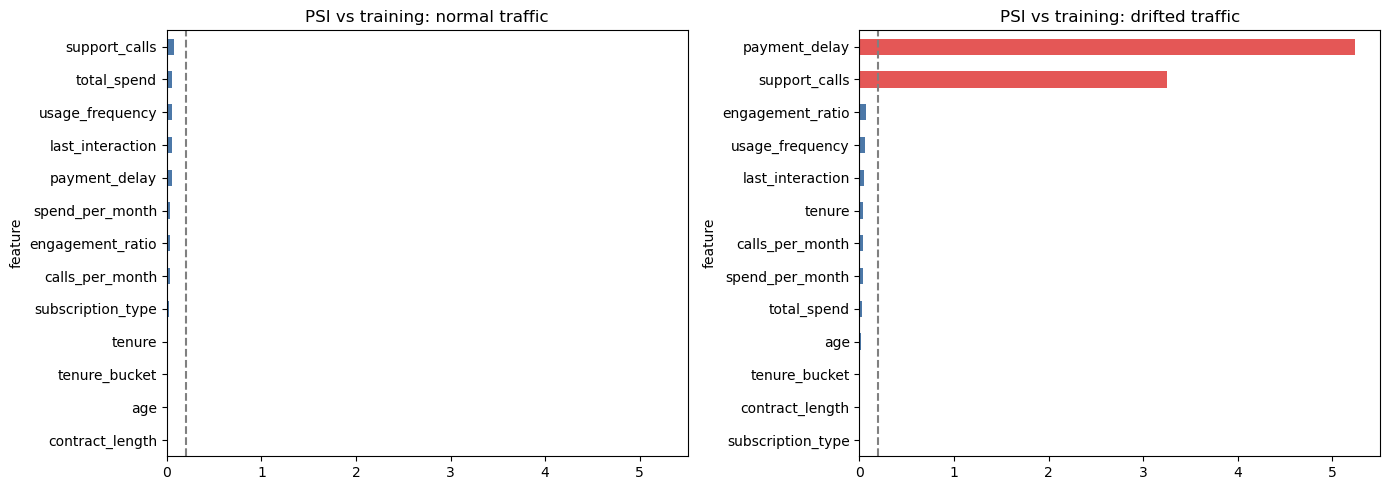

,feature,psi,drifted
0,payment_delay,5.243237,True
1,support_calls,3.247753,True
2,engagement_ratio,0.064556,False
3,usage_frequency,0.055649,False
4,last_interaction,0.044068,False
5,tenure,0.041014,False


In [4]:
reports = {
    "normal": monitoring.drift_report(train_df, normal, features.NUMERIC_FEATURES, features.CATEGORICAL_FEATURES),
    "drifted": monitoring.drift_report(train_df, drifted, features.NUMERIC_FEATURES, features.CATEGORICAL_FEATURES),
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, (name, report) in zip(axes, reports.items()):
    ordered = report.sort_values("psi")
    ordered.set_index("feature")["psi"].plot(
        kind="barh", ax=ax, color=["#e45756" if d else "#4c78a8" for d in ordered["drifted"]]
    )
    ax.axvline(monitoring.PSI_ALERT, ls="--", c="gray")
    ax.set_title(f"PSI vs training: {name} traffic")
plt.tight_layout()
figure_path = REPO_ROOT / "docs" / "figures" / "drift_psi.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(figure_path, dpi=150)
plt.show()
reports["drifted"].head(6)


## 4. Model-quality baseline, ground truth, and schedule


In [5]:
base_rows = test_df.sample(min(1000, len(test_df)), random_state=3)
preds = invoke(base_rows)
baseline = pd.DataFrame({
    "prediction": preds["prediction"].values,
    "probability": preds["probability"].values,
    "label": base_rows["churn"].astype(int).values,
})
mq_baseline_path = f"{MON}/baseline/model_quality_baseline.csv"
wr.s3.to_csv(baseline, path=mq_baseline_path, index=False)

model_monitor = ModelQualityMonitor(
    role=role, instance_count=1, instance_type="ml.m5.xlarge",
    volume_size_in_gb=20, max_runtime_in_seconds=1800, sagemaker_session=session,
)
model_monitor.suggest_baseline(
    baseline_dataset=mq_baseline_path,
    dataset_format=DatasetFormat.csv(header=True),
    output_s3_uri=f"{MON}/baseline/model-quality",
    problem_type="BinaryClassification",
    inference_attribute="prediction", probability_attribute="probability",
    ground_truth_attribute="label", wait=True,
)
model_monitor.baseline_statistics().body_dict["binary_classification_metrics"]["auc"]


[10/19/26 12:47:31] INFO     Ignoring unnecessary instance type: None.                            ]8;id=8369139;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/image_uris.py\image_uris.py]8;;\:]8;id=8369140;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/image_uris.py#535\535]8;;\

                    INFO     Creating processing-job with name                                    ]8;id=8369145;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/processing.py\processing.py]8;;\:]8;id=8369146;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/processing.py#617\617]8;;\
                             baseline-suggestion-job-2026-10-19-12-47-31-890                                       

Output()

[10/19/26 12:52:39] INFO     Final Resource Status: Completed                                    ]8;id=8369151;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=8369152;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#29099\29099]8;;\

{'value': 0.9977019946686276, 'standard_deviation': 0.000992894148270603}

In [7]:
labelled = production.sample(min(400, len(production)), random_state=4)
ids = [f"gt-{i}" for i in labelled["customer_id"]]
invoke(labelled, ids=ids)

now = dt.datetime.now(dt.timezone.utc)
gt_prefix = f"{config.MONITOR_PREFIX}/ground-truth/{now:%Y/%m/%d/%H}/"
records = [
    {"groundTruthData": {"data": str(int(label)), "encoding": "CSV"},
     "eventMetadata": {"eventId": event_id}, "eventVersion": "0"}
    for event_id, label in zip(ids, labelled["churn"])
]
s3.put_object(
    Bucket=BUCKET, Key=gt_prefix + "ground_truth.jsonl",
    Body="\n".join(json.dumps(record) for record in records).encode(),
)

schedule_name = "churn-model-quality-schedule"
existing = {x["MonitoringScheduleName"] for x in session.sagemaker_client.list_monitoring_schedules()["MonitoringScheduleSummaries"]}
if schedule_name in existing:
    model_monitor = ModelQualityMonitor.attach(schedule_name, sagemaker_session=session)
    print("attached to existing schedule")
else:
    model_monitor.create_monitoring_schedule(
        monitor_schedule_name=schedule_name,
        endpoint_input=EndpointInput(
            endpoint_name=config.ENDPOINT_NAME,
            destination="/opt/ml/processing/input_data",
            probability_attribute="0",
            probability_threshold_attribute=float(latest["threshold"]),
            inference_attribute="1",
        ),
        ground_truth_input=f"{MON}/ground-truth",
        problem_type="BinaryClassification",
        constraints=model_monitor.suggested_constraints(),
        output_s3_uri=f"{MON}/reports/model-quality",
        schedule_cron_expression=CronExpressionGenerator.hourly(),
        enable_cloudwatch_metrics=True,
    )
    print("created", schedule_name)


╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:23                                                                                   │
│                                                                                                  │
│   20 │   model_monitor = ModelQualityMonitor.attach(schedule_name, sagemaker_session=session)    │
│   21 │   print("attached to existing schedule")                                                  │
│   22 else:                                                                                       │
│ ❱ 23 │   model_monitor.create_monitoring_schedule(                                               │
│   24 │   │   monitor_schedule_name=schedule_name,                                                │
│   25 │   │   endpoint_input=EndpointInput(                                                       │
│   26 │   │   │   endpoint_name=config.ENDPOINT_NAME,                                             │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/sagemaker/core/model_monitor/model_monitoring.py:3238 in │
│ create_monitoring_schedule                                                                       │
│                                                                                                  │
│   3235 │   │   │   network_config=self.network_config,                                           │
│   3236 │   │   │   batch_transform_input=batch_transform_input,                                  │
│   3237 │   │   )                                                                                 │
│ ❱ 3238 │   │   self.sagemaker_session.sagemaker_client.create_model_quality_job_definition(**re  │
│   3239 │   │                                                                                     │
│   3240 │   │   # create schedule                                                                 │
│   3241 │   │   try:                                                                              │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/botocore/client.py:606 in _api_call                      │
│                                                                                                  │
│    603 │   │   │   │   │   f"{py_operation_name}() only accepts keyword arguments."              │
│    604 │   │   │   │   )                                                                         │
│    605 │   │   │   # The "self" in this scope is referring to the BaseClient.                    │
│ ❱  606 │   │   │   return self._make_api_call(operation_name, kwargs)                            │
│    607 │   │                                                                                     │
│    608 │   │   _api_call.__name__ = str(py_operation_name)                                       │
│    609                                                                                           │
│                                                                                                  │
│ /opt/conda/lib/python3.12/site-packages/botocore/context.py:123 in wrapper                       │
│                                                                                                  │
│   120 │   │   │   with start_as_current_context():                                               │
│   121 │   │   │   │   if hook:                                                                   │
│   122 │   │   │   │   │   hook()                                                                 │
│ ❱ 123 │   │   │   │   return func(*args, **kwargs)                                               │
│   124 │   │                                                                                      │
│   125 │   │   return wrapper                               

## 5. CloudWatch dashboard and alarms


In [ ]:
cw = boto3.client("cloudwatch", region_name=REGION)
variant = ["EndpointName", config.ENDPOINT_NAME, "VariantName", "AllTraffic"]

def widget(title, metric, stat, x, y, namespace="/aws/sagemaker/Endpoints"):
    return {"type": "metric", "x": x, "y": y, "width": 12, "height": 6,
            "properties": {"title": title, "region": REGION, "stat": stat, "period": 300,
                           "metrics": [[namespace, metric, *variant]]}}

dashboard = {"widgets": [
    widget("Invocations", "Invocations", "Sum", 0, 0, "AWS/SageMaker"),
    widget("Model latency", "ModelLatency", "Average", 12, 0, "AWS/SageMaker"),
    widget("5XX errors", "Invocation5XXErrors", "Sum", 0, 6, "AWS/SageMaker"),
    widget("4XX errors", "Invocation4XXErrors", "Sum", 12, 6, "AWS/SageMaker"),
    widget("CPU utilization", "CPUUtilization", "Average", 0, 12),
    widget("Memory utilization", "MemoryUtilization", "Average", 12, 12),
]}
cw.put_dashboard(DashboardName="churn-endpoint-dashboard", DashboardBody=json.dumps(dashboard))

dims = [{"Name": "EndpointName", "Value": config.ENDPOINT_NAME}, {"Name": "VariantName", "Value": "AllTraffic"}]
cw.put_metric_alarm(AlarmName="churn-endpoint-5xx", Namespace="AWS/SageMaker", MetricName="Invocation5XXErrors",
                    Dimensions=dims, Statistic="Sum", Period=300, EvaluationPeriods=1, Threshold=1,
                    ComparisonOperator="GreaterThanOrEqualToThreshold", TreatMissingData="notBreaching")
cw.put_metric_alarm(AlarmName="churn-endpoint-latency", Namespace="AWS/SageMaker", MetricName="ModelLatency",
                    Dimensions=dims, Statistic="Average", Period=300, EvaluationPeriods=2, Threshold=500_000,
                    ComparisonOperator="GreaterThanThreshold", TreatMissingData="notBreaching")
print(f"https://{REGION}.console.aws.amazon.com/cloudwatch/home?region={REGION}#dashboards:name=churn-endpoint-dashboard")


## 6. Latest reports (run after the next full hour)


In [ ]:
for label, monitor_object in [("data quality", data_monitor), ("model quality", model_monitor)]:
    print(f"--- {label} ---")
    try:
        execution = monitor_object.describe_latest_execution()
        print("status:", execution.get("ProcessingJobStatus"), "|", execution.get("ExitMessage", ""))
        violations = monitor_object.latest_monitoring_constraint_violations().body_dict["violations"]
        print(pd.DataFrame(violations) if violations else "no violations")
    except Exception as error:
        print("no completed report yet:", str(error)[:160])


Cleanup after the demo:

```python
data_monitor.delete_monitoring_schedule()
model_monitor.delete_monitoring_schedule()
```


In [1]:
%%html

<p><b>Shutting down your kernel for this notebook to release resources.</b></p>
<button class="sm-command-button" data-commandlinker-command="kernelmenu:shutdown" style="display:none;">Shutdown Kernel</button>
        
<script>
try {
    els = document.getElementsByClassName("sm-command-button");
    els[0].click();
}
catch(err) {
    // NoOp
}    
</script>
